# 02 - Feature ablation

Does a change to the model actually help, or did the number just move?

Every comparison here runs through `experiments.compare_configs`, which
enforces two things that are easy to get wrong by hand:

1. **Configs are scored on the same fixtures.** A variant that skips matches
   would otherwise be judged on an easier subset.
2. **Differences get a paired bootstrap CI, not just a point estimate.** One
   season is ~380 matches per league. Differences of 0.01-0.02 nats are
   routinely indistinguishable from noise at that sample size, and reading
   them as real is the single easiest way to talk yourself into a feature
   that does nothing.

Losses are pooled across leagues at the per-match level, so more leagues
means more power - which is the main reason to run this on all five.

In [1]:
import warnings, logging
logging.getLogger("soccerdata").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hattrick.experiments import ModelConfig, compare_configs, format_comparison, load_leagues

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})

matches_by_league, is_real = load_leagues()
all_dates = pd.concat([m["date"] for m in matches_by_league.values()])
HOLDOUT_START = "2025-08-01" if is_real else str(all_dates.quantile(0.7).date())
print(f"\n{'REAL' if is_real else 'SYNTHETIC'} data, holdout from {HOLDOUT_START}")

E0: 1530 matches, xG coverage 100.0% (from matches.csv)
SP1: 1540 matches, xG coverage 100.0% (from matches.csv)
I1: 1530 matches, xG coverage 99.9% (from matches.csv)
D1: 1224 matches, xG coverage 100.0% (from matches.csv)
F1: 1307 matches, xG coverage 99.9% (from matches.csv)

REAL data, holdout from 2025-08-01


## The configurations

- **baseline** - current defaults: goals target, partial pooling on.
- **no partial pooling** - the pre-fix behavior. Expect this to be worse;
  it is the fit that used to drive promoted teams' ratings to the boundary.
- **xG target** - fit the rates on expected goals, falling back to goals per
  match where xG is missing. rho still comes from actual scorelines.
- **faster / slower decay** - `xi` controls how quickly old matches are
  forgotten (`exp(-xi * days)`). Included because a less noisy target
  arguably wants a shorter memory, so it is a confound worth ruling out
  rather than an interesting feature in itself.

On five leagues x four seasons this cell takes roughly 20-40 minutes. Cut
`CONFIGS` or the league list in `load_leagues(...)` if you want it faster.

In [2]:
CONFIGS = [
    ModelConfig("baseline (goals)"),
    ModelConfig("no partial pooling", model_kwargs=dict(prior_strength=0.0, rating_prior_sd=None)),
    ModelConfig("xG target", model_kwargs=dict(target="xg")),
    ModelConfig("faster decay (xi=0.003)", xi=0.0030),
    ModelConfig("slower decay (xi=0.0009)", xi=0.0009),
]
for c in CONFIGS:
    print(f"{c.name:28s} xi={c.xi:<8} {c.model_kwargs}")

baseline (goals)             xi=0.0018   {}
no partial pooling           xi=0.0018   {'prior_strength': 0.0, 'rating_prior_sd': None}
xG target                    xi=0.0018   {'target': 'xg'}
faster decay (xi=0.003)      xi=0.003    {}
slower decay (xi=0.0009)     xi=0.0009   {}


In [3]:
%%time
# refit_every=20 rather than the default 10: this runs 5 configs x 5 leagues,
# and refitting after every 10th match doubles the cost for a change that is
# well below the noise floor of the comparison.
table = compare_configs(matches_by_league, CONFIGS,
                        holdout_start=HOLDOUT_START, refit_every=20,
                        baseline="baseline (goals)", n_boot=10_000, seed=0)
print(format_comparison(table))

Baseline: baseline (goals)   (metric: log_loss, lower is better)
Market benchmark: 0.9768 (n=1781)

  baseline (goals)             0.9936   (baseline, n=1781)
  no partial pooling           1.0013   +0.0077 [-0.0008, +0.0188] p=0.085  -> worse, not distinguishable from noise
  xG target                    0.9953   +0.0017 [-0.0037, +0.0072] p=0.537  -> worse, not distinguishable from noise
  faster decay (xi=0.003)      0.9964   +0.0029 [+0.0007, +0.0050] p=0.008  -> worse, SIGNIFICANT
  slower decay (xi=0.0009)     0.9923   -0.0012 [-0.0032, +0.0007] p=0.205  -> better, not distinguishable from noise
CPU times: user 11min 22s, sys: 5.63 s, total: 11min 28s
Wall time: 2min 32s


## Read the intervals, not the point estimates

The bars are the change in log loss versus baseline (negative = better) and
the whiskers are the 95% bootstrap CI. **Any bar whose interval crosses zero
is not evidence of anything.**

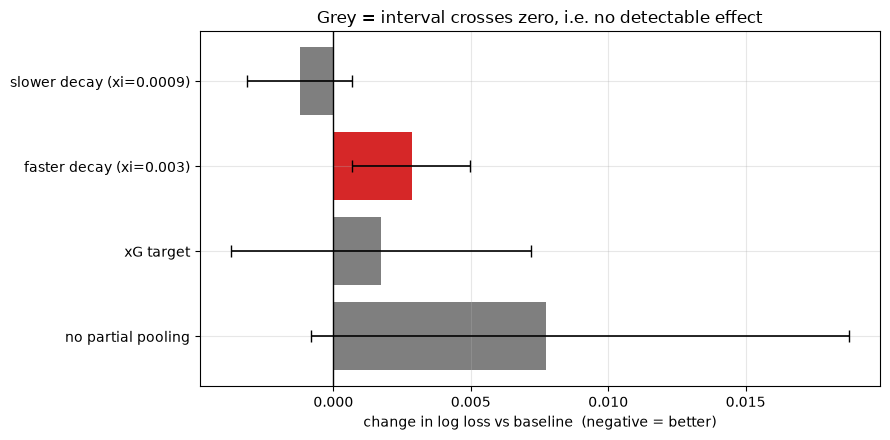

In [4]:
d = table[table["config"] != table.attrs["baseline"]]
fig, ax = plt.subplots()
y = np.arange(len(d))
ax.barh(y, d["vs_baseline"],
        color=["tab:green" if s and v < 0 else "tab:red" if s else "tab:gray"
               for s, v in zip(d["significant"], d["vs_baseline"])])
ax.errorbar(d["vs_baseline"], y,
            xerr=[d["vs_baseline"] - d["ci_low"], d["ci_high"] - d["vs_baseline"]],
            fmt="none", ecolor="k", capsize=4, lw=1.2)
ax.axvline(0, color="k", lw=1)
ax.set_yticks(y, d["config"])
ax.set_xlabel("change in log loss vs baseline  (negative = better)")
ax.set_title("Grey = interval crosses zero, i.e. no detectable effect")
plt.tight_layout(); plt.show()

## Per-league breakdown

An effect that is real should at least point the same way in most leagues.
One league carrying the whole result is a sign of noise, not a feature.

In [5]:
per_league = table.attrs["per_league"]
pivot = per_league.pivot(index="league", columns="config", values="log_loss")
base = table.attrs["baseline"]
delta = pivot.sub(pivot[base], axis=0).drop(columns=[base])
display(delta.style.format("{:+.4f}").background_gradient(cmap="RdYlGn_r", axis=None))
print("\nNegative = better than baseline in that league.")

config,faster decay (xi=0.003),no partial pooling,slower decay (xi=0.0009),xG target
league,,,,
D1,+0.0042,+0.0252,-0.0024,+0.0020
E0,+0.0021,-0.0013,-0.0000,+0.0015
F1,+0.0052,+0.0124,-0.0036,-0.0055
I1,+0.0026,-0.0032,-0.0020,+0.0074
SP1,+0.0010,+0.0102,+0.0011,+0.0019



Negative = better than baseline in that league.


## How many matches would it take?

If a difference is too small to resolve, it is worth knowing how much data
*would* resolve it before spending more effort on the feature. The bootstrap
standard error scales as 1/sqrt(n), so this is a rough but useful guide.

In [6]:
rows = []
for r in table.itertuples():
    if r.config == base or not np.isfinite(r.ci_low):
        continue
    se = (r.ci_high - r.ci_low) / (2 * 1.96)
    needed = (1.96 * se / abs(r.vs_baseline)) ** 2 * r.n_matches if r.vs_baseline else np.inf
    rows.append({"config": r.config, "effect": r.vs_baseline, "se": se,
                 "n_now": r.n_matches,
                 "n_for_significance": round(needed) if np.isfinite(needed) else None})
display(pd.DataFrame(rows).style.format({"effect": "{:+.4f}", "se": "{:.4f}"}))

,config,effect,se,n_now,n_for_significance
0,no partial pooling,+0.0077,0.0050,1781,2851
1,xG target,+0.0017,0.0028,1781,17881
2,faster decay (xi=0.003),+0.0029,0.0011,1781,1010
3,slower decay (xi=0.0009),-0.0012,0.0010,1781,4362
